In [ ]:
import math
import random

N = 8

# --------------------------------------------------
# COST FUNCTION
# --------------------------------------------------
def cost(board):
    conflicts = 0

    for i in range(N):
        for j in range(i + 1, N):

            # Same row
            if board[i] == board[j]:
                conflicts += 1

            # Same diagonal
            elif abs(board[i] - board[j]) == abs(i - j):
                conflicts += 1

    return conflicts


# --------------------------------------------------
# DISPLAY BOARD
# --------------------------------------------------
def display_board(board):

    for row in range(N):

        for col in range(N):

            if board[col] == row:
                print("Q", end=" ")
            else:
                print(".", end=" ")

        print()


# --------------------------------------------------
# INITIAL BOARD
# --------------------------------------------------

current = [0, 4, 7, 5, 2, 6, 3, 1]

T = 5.0
alpha = 0.90

print("INITIAL BOARD")
print(current)
print("Initial Cost =", cost(current))

display_board(current)


# --------------------------------------------------
# FIXED MOVES FOR EASY DEMONSTRATION
# --------------------------------------------------

moves = [
    (6, 1),   # iteration 1
    (7, 3),   # iteration 2
    (5, 4),   # iteration 3
    (2, 6),   # iteration 4
    (3, 2),   # iteration 5
    (0, 1),   # iteration 6
    (4, 3),   # iteration 7
    (5, 7),   # iteration 8
    (6, 2),   # iteration 9
    (7, 3)    # iteration 10
]


# --------------------------------------------------
# SIMULATED ANNEALING
# --------------------------------------------------

for iteration in range(1, 11):

    current_cost = cost(current)

    # Make a copy
    new_board = current.copy()

    # Select predetermined move
    column, new_row = moves[iteration - 1]

    old_row = new_board[column]

    # Move queen
    new_board[column] = new_row

    new_cost = cost(new_board)

    delta_E = new_cost - current_cost

    # ----------------------------------------------
    # ACCEPTANCE
    # ----------------------------------------------

    if delta_E < 0:

        probability = 1
        random_number = 0
        accepted = True
        decision = "ACCEPT - BETTER"

    else:

        probability = math.exp(-delta_E / T)

        random_number = random.random()

        if random_number < probability:
            accepted = True
            decision = "ACCEPT - WORSE"
        else:
            accepted = False
            decision = "REJECT"

    # ----------------------------------------------
    # DISPLAY
    # ----------------------------------------------

    print("\n" + "=" * 55)

    print("ITERATION:", iteration)

    print("Temperature:", round(T, 3))

    print("\nCurrent Board:")
    print(current)

    print("Current Cost:", current_cost)

    print("\nMove:")
    print("Column", column,
          ":", old_row, "->", new_row)

    print("\nNew Board:")
    print(new_board)

    print("New Cost:", new_cost)

    print("ΔE =", delta_E)

    print("Acceptance Probability:",
          round(probability, 4))

    if delta_E >= 0:
        print("Random Number:",
              round(random_number, 4))

    print("DECISION:", decision)

    # ----------------------------------------------
    # UPDATE BOARD
    # ----------------------------------------------

    if accepted:
        current = new_board

    # ----------------------------------------------
    # COOLING
    # ----------------------------------------------

    T = T * alpha

    # Stop if solution found
    if cost(current) == 0:

        print("\n🎉 SOLUTION FOUND!")

        print("Solved in", iteration, "iterations")

        break


# --------------------------------------------------
# FINAL RESULT
# --------------------------------------------------

print("\n" + "=" * 55)
print("FINAL RESULT")
print("=" * 55)

print("Final Board:", current)
print("Final Cost:", cost(current))

print("\nFinal Chess Board:")
display_board(current)

INITIAL BOARD
[0, 4, 7, 5, 2, 6, 3, 1]
Initial Cost = 2
Q . . . . . . . 
. . . . . . . Q 
. . . . Q . . . 
. . . . . . Q . 
. Q . . . . . . 
. . . Q . . . . 
. . . . . Q . . 
. . Q . . . . . 

ITERATION: 1
Temperature: 5.0

Current Board:
[0, 4, 7, 5, 2, 6, 3, 1]
Current Cost: 2

Move:
Column 6 : 3 -> 1

New Board:
[0, 4, 7, 5, 2, 6, 1, 1]
New Cost: 2
ΔE = 0
Acceptance Probability: 1.0
Random Number: 0.8749
DECISION: ACCEPT - WORSE

ITERATION: 2
Temperature: 4.5

Current Board:
[0, 4, 7, 5, 2, 6, 1, 1]
Current Cost: 2

Move:
Column 7 : 1 -> 3

New Board:
[0, 4, 7, 5, 2, 6, 1, 3]
New Cost: 0
ΔE = -2
Acceptance Probability: 1
DECISION: ACCEPT - BETTER

🎉 SOLUTION FOUND!
Solved in 2 iterations

FINAL RESULT
Final Board: [0, 4, 7, 5, 2, 6, 1, 3]
Final Cost: 0

Final Chess Board:
Q . . . . . . . 
. . . . . . Q . 
. . . . Q . . . 
. . . . . . . Q 
. Q . . . . . . 
. . . Q . . . . 
. . . . . Q . . 
. . Q . . . . . 


In [ ]:

import random
import math

# Function to calculate conflicts
def calculate_cost(board):
    conflicts = 0

    for i in range(8):
        for j in range(i + 1, 8):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                conflicts += 1

    return conflicts


# Generate a random neighbouring state
def generate_neighbor(board):
    neighbor = board.copy()

    col = random.randint(0, 7)
    row = random.randint(0, 7)

    while row == neighbor[col]:
        row = random.randint(0, 7)

    neighbor[col] = row
    return neighbor


# Simulated Annealing algorithm
def simulated_annealing(current, temperature, cooling_rate, iterations):

    print("\nInitial Configuration:", current)
    print("Initial Conflicts:", calculate_cost(current))

    print("\nIteration Details:")
    print("-" * 85)
    print(f"{'Iter':<8}{'Temp':<12}{'Current':<12}{'Neighbor':<12}{'Delta E':<12}{'P':<12}{'Decision'}")
    print("-" * 85)

    for i in range(1, iterations + 1):

        if temperature <= 0:
            break

        current_cost = calculate_cost(current)

        neighbor = generate_neighbor(current)
        neighbor_cost = calculate_cost(neighbor)

        # Delta E = Current Cost - Neighbor Cost
        delta = current_cost - neighbor_cost

        # Calculate acceptance probability
        if delta >= 0:
            probability = 1.0
            current = neighbor
            decision = "Accepted"

        else:
            probability = math.exp(delta / temperature)

            if random.random() < probability:
                current = neighbor
                decision = "Accepted"
            else:
                decision = "Rejected"

        print(f"{i:<8}{temperature:<12.2f}{current_cost:<12}"
              f"{neighbor_cost:<12}{delta:<12}"
              f"{probability:<12.4f}{decision}")

        # Decrease temperature
        temperature *= cooling_rate

    return current


# Main program
print("SIMULATED ANNEALING - 8 QUEENS PROBLEM")

initial = list(map(int, input("Enter 8 row positions (0-7): ").split()))

if len(initial) != 8 or any(x < 0 or x > 7 for x in initial):
    print("Invalid configuration!")
else:
    temperature = float(input("Enter initial temperature: "))
    cooling_rate = float(input("Enter cooling rate: "))
    iterations = int(input("Enter maximum iterations: "))

    result = simulated_annealing(
        initial, temperature, cooling_rate, iterations
    )

    print("\nFinal Result:")
    print("Initial Configuration:", initial)
    print("Final Configuration:", result)

    final_cost = calculate_cost(result)

    print("Number of Conflicts:", final_cost)
    print("Total Iterations:", iterations)

    if final_cost == 0:
        print("Status: Solution Found")
    else:
        print("Status: Solution Not Found")


SIMULATED ANNEALING - 8 QUEENS PROBLEM
Enter 8 row positions (0-7): 0 2 4 6 1 3 5 7
Enter initial temperature: 1000
Enter cooling rate: 0.95
Enter maximum iterations: 150

Initial Configuration: [0, 2, 4, 6, 1, 3, 5, 7]
Initial Conflicts: 1

Iteration Details:
-------------------------------------------------------------------------------------
Iter    Temp        Current     Neighbor    Delta E     P           Decision
-------------------------------------------------------------------------------------
1       1000.00     1           2           -1          0.9990      Accepted
2       950.00      2           2           0           1.0000      Accepted
3       902.50      2           2           0           1.0000      Accepted
4       857.38      2           5           -3          0.9965      Accepted
5       814.51      5           7           -2          0.9975      Accepted
6       773.78      7           7           0           1.0000      Accepted
7       735.09      7       

SIMULATED ANNEALING - 8 QUEENS PROBLEM
Enter 8 row positions (0-7): 0 2 4 6 1 3 5 7
Enter initial temperature: 1000
Enter cooling rate: 0.95
Enter maximum iterations: 150

Initial Configuration: [0, 2, 4, 6, 1, 3, 5, 7]
Initial Conflicts: 1

Iteration Details:
-------------------------------------------------------------------------------------
Iter    Temp        Current     Neighbor    Delta E     P           Decision
-------------------------------------------------------------------------------------
1       1000.00     1           4           -3          0.9970      Accepted
2       950.00      4           5           -1          0.9989      Accepted
3       902.50      5           5           0           1.0000      Accepted
4       857.38      5           5           0           1.0000      Accepted
5       814.51      5           6           -1          0.9988      Accepted
6       773.78      6           4           2           1.0000      Accepted
7       735.09      4       

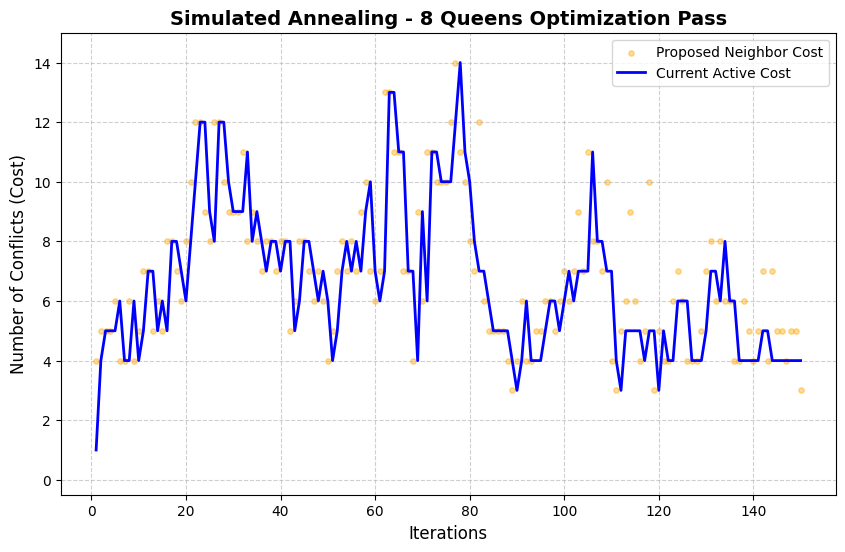


Final Result:
Initial Configuration: [0, 2, 4, 6, 1, 3, 5, 7]
Final Configuration: [5, 2, 4, 7, 3, 0, 6, 3]
Number of Conflicts: 3
Total Iterations: 150
Status: Solution Not Found


In [ ]:
import random
import math
import matplotlib.pyplot as plt  # Added for plotting

# Function to calculate conflicts
def calculate_cost(board):
    conflicts = 0
    for i in range(8):
        for j in range(i + 1, 8):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                conflicts += 1
    return conflicts

# Generate a random neighbouring state
def generate_neighbor(board):
    neighbor = board.copy()
    col = random.randint(0, 7)
    row = random.randint(0, 7)
    while row == neighbor[col]:
        row = random.randint(0, 7)
    neighbor[col] = row
    return neighbor

# Simulated Annealing algorithm
def simulated_annealing(current, temperature, cooling_rate, iterations):
    print("\nInitial Configuration:", current)
    print("Initial Conflicts:", calculate_cost(current))

    print("\nIteration Details:")
    print("-" * 85)
    print(f"{'Iter':<8}{'Temp':<12}{'Current':<12}{'Neighbor':<12}{'Delta E':<12}{'P':<12}{'Decision'}")
    print("-" * 85)

    # Lists to store metrics for the graph
    history_iterations = []
    history_current_cost = []
    history_neighbor_cost = []

    for i in range(1, iterations + 1):
        if temperature <= 0:
            break

        current_cost = calculate_cost(current)
        neighbor = generate_neighbor(current)
        neighbor_cost = calculate_cost(neighbor)

        # Delta E = Current Cost - Neighbor Cost
        delta = current_cost - neighbor_cost

        # Calculate acceptance probability
        if delta >= 0:
            probability = 1.0
            current = neighbor
            decision = "Accepted"
        else:
            probability = math.exp(delta / temperature)
            if random.random() < probability:
                current = neighbor
                decision = "Accepted"
            else:
                decision = "Rejected"

        print(f"{i:<8}{temperature:<12.2f}{current_cost:<12}"
              f"{neighbor_cost:<12}{delta:<12}"
              f"{probability:<12.4f}{decision}")

        # Record metrics for tracking
        history_iterations.append(i)
        history_current_cost.append(current_cost)
        history_neighbor_cost.append(neighbor_cost)

        # Decrease temperature
        temperature *= cooling_rate

    # Plotting the results
    plt.figure(figsize=(10, 6))

    # Plot neighbor proposals as light dots to see the exploration boundaries
    plt.scatter(history_iterations, history_neighbor_cost, color='orange', alpha=0.4, label='Proposed Neighbor Cost', s=15)

    # Plot the active state path as a solid distinct step line
    plt.plot(history_iterations, history_current_cost, color='blue', linewidth=2, label='Current Active Cost')

    plt.title('Simulated Annealing - 8 Queens Optimization Pass', fontsize=14, fontweight='bold')
    plt.xlabel('Iterations', fontsize=12)
    plt.ylabel('Number of Conflicts (Cost)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper right')
    plt.ylim(-0.5, max(max(history_current_cost), max(history_neighbor_cost)) + 1)

    # Automatically display the graph modal window
    plt.show()

    return current

# Main program
print("SIMULATED ANNEALING - 8 QUEENS PROBLEM")
initial = list(map(int, input("Enter 8 row positions (0-7): ").split()))

if len(initial) != 8 or any(x < 0 or x > 7 for x in initial):
    print("Invalid configuration!")
else:
    temperature = float(input("Enter initial temperature: "))
    cooling_rate = float(input("Enter cooling rate: "))
    iterations = int(input("Enter maximum iterations: "))

    result = simulated_annealing(
        initial, temperature, cooling_rate, iterations
    )

    print("\nFinal Result:")
    print("Initial Configuration:", initial)
    print("Final Configuration:", result)

    final_cost = calculate_cost(result)
    print("Number of Conflicts:", final_cost)
    print("Total Iterations:", iterations)

    if final_cost == 0:
        print("Status: Solution Found")
    else:
        print("Status: Solution Not Found")

